# Breast Ultrasound Classification Using EfficientNet-B3 Ensemble and Grad-CAM

**MD. Shadhin Khan · Ali Emam Rabby · Sristi Sorower**
Department of Computer Science & Engineering, First Capital University of Bangladesh

## 1. Setup

In [ ]:
import zipfile, random
from pathlib import Path
from collections import Counter
import numpy as np
import torch, torch.nn as nn
from torch.utils.data import DataLoader, Dataset
from torchvision import transforms, models
from PIL import Image
from google.colab import drive

drive.mount('/content/drive')
zip_path = Path('/content/drive/MyDrive/Cancer/archive.zip')
if not zip_path.exists():
    zip_path = next(Path('/content/drive/MyDrive').rglob('archive.zip'))
if not Path('/content/data/Dataset_BUSI_with_GT').exists():
    with zipfile.ZipFile(zip_path) as z:
        z.extractall('/content/data')
ROOT = Path('/content/data/Dataset_BUSI_with_GT')
device = 'cuda' if torch.cuda.is_available() else 'cpu'
print('device:', device)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
device: cuda


## 2. Dataset

The BUSI dataset has 780 ultrasound images in three classes: normal, benign and malignant.

In [ ]:
classes = ['normal', 'benign', 'malignant']
samples = []
for ci, cls in enumerate(classes):
    for p in sorted((ROOT / cls).glob('*.png')):
        if '_mask' not in p.stem:
            samples.append((p, ci))
print('total images:', len(samples))
print(Counter(y for _, y in samples))

total images: 780
Counter({1: 437, 2: 210, 0: 133})


## 3. Train and Test Split

In [ ]:
from sklearn.model_selection import train_test_split

labels = np.array([y for _, y in samples])
idx = np.arange(len(samples))
train_idx, tmp = train_test_split(idx, test_size=0.30, stratify=labels, random_state=42)
val_idx, test_idx = train_test_split(tmp, test_size=0.50, stratify=labels[tmp], random_state=42)
train_items = [samples[i] for i in sorted(np.concatenate([train_idx, val_idx]))]
test_items = [samples[i] for i in test_idx]
print('train:', len(train_items), ' test:', len(test_items))
print('test classes:', Counter(labels[test_idx]))

train: 663  test: 117
test classes: Counter({np.int64(1): 66, np.int64(2): 31, np.int64(0): 20})


## 4. Model and Training Function

In [ ]:
MEAN, STD = [0.485, 0.456, 0.406], [0.229, 0.224, 0.225]
train_tf = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomVerticalFlip(p=0.3),
    transforms.RandomRotation(15),
    transforms.RandomAffine(0, translate=(0.05, 0.05), scale=(0.95, 1.05)),
    transforms.ColorJitter(brightness=0.15, contrast=0.15),
    transforms.ToTensor(), transforms.Normalize(MEAN, STD)])
test_tf = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(), transforms.Normalize(MEAN, STD)])

class BUSI(Dataset):
    def __init__(self, items, tf):
        self.items, self.tf = items, tf
    def __len__(self):
        return len(self.items)
    def __getitem__(self, i):
        p, y = self.items[i]
        return self.tf(Image.open(p).convert('RGB')), y

counts = np.bincount([y for _, y in train_items], minlength=3)
weights = torch.tensor(counts.sum() / (3 * counts), dtype=torch.float).to(device)
print('class weights:', [round(w, 2) for w in weights.tolist()])

def make_model():
    m = models.efficientnet_b3(weights=models.EfficientNet_B3_Weights.IMAGENET1K_V1)
    m.classifier[1] = nn.Linear(m.classifier[1].in_features, 3)
    return m.to(device)

def train_model(seed):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed)
    model = make_model()
    from torch.optim.swa_utils import AveragedModel
    ema = AveragedModel(model, avg_fn=lambda a, c, n: 0.99 * a + 0.01 * c)
    loss_fn = nn.CrossEntropyLoss(weight=weights, label_smoothing=0.05)
    opt = torch.optim.AdamW(model.parameters(), lr=2e-4, weight_decay=1e-4)
    sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=30)
    loader = DataLoader(BUSI(train_items, train_tf), batch_size=16, shuffle=True, num_workers=2)
    hist = []
    for epoch in range(30):
        model.train(); total = 0
        for x, y in loader:
            x, y = x.to(device), y.to(device)
            opt.zero_grad()
            loss = loss_fn(model(x), y)
            loss.backward(); opt.step()
            if epoch >= 2:
                ema.update_parameters(model)
            total += loss.item() * len(x)
        sched.step()
        hist.append(total / len(train_items))
        print(f'seed {seed}  epoch {epoch + 1}/30  loss {hist[-1]:.4f}')
    return ema.module, hist

@torch.no_grad()
def predict(model, items):
    model.eval()
    loader = DataLoader(BUSI(items, test_tf), batch_size=32, num_workers=2)
    out = []
    for x, y in loader:
        out.append(torch.softmax(model(x.to(device)), 1).cpu().numpy())
    return np.concatenate(out)

class weights: [1.96, 0.6, 1.23]


## 5. Training the Three Models

Each model trains for 30 epochs.

In [ ]:
trained, histories, probs_list = [], [], []
y_true = np.array([y for _, y in test_items])

In [ ]:
model, hist = train_model(42)
trained.append(model); histories.append(hist)
p = predict(model, test_items); probs_list.append(p)
print('seed 42 test accuracy:', round((p.argmax(1) == y_true).mean() * 100, 2), '%')

seed 42  epoch 1/30  loss 1.0252
seed 42  epoch 2/30  loss 0.7354
seed 42  epoch 3/30  loss 0.6088
seed 42  epoch 4/30  loss 0.4900
seed 42  epoch 5/30  loss 0.4735
seed 42  epoch 6/30  loss 0.4471
seed 42  epoch 7/30  loss 0.4087
seed 42  epoch 8/30  loss 0.4037
seed 42  epoch 9/30  loss 0.3571
seed 42  epoch 10/30  loss 0.3757
seed 42  epoch 11/30  loss 0.3451
seed 42  epoch 12/30  loss 0.3276
seed 42  epoch 13/30  loss 0.3462
seed 42  epoch 14/30  loss 0.3185
seed 42  epoch 15/30  loss 0.3258
seed 42  epoch 16/30  loss 0.3058
seed 42  epoch 17/30  loss 0.2835
seed 42  epoch 18/30  loss 0.2807
seed 42  epoch 19/30  loss 0.2877
seed 42  epoch 20/30  loss 0.2811
seed 42  epoch 21/30  loss 0.2733
seed 42  epoch 22/30  loss 0.2842
seed 42  epoch 23/30  loss 0.2681
seed 42  epoch 24/30  loss 0.2805
seed 42  epoch 25/30  loss 0.2646
seed 42  epoch 26/30  loss 0.2741
seed 42  epoch 27/30  loss 0.2648
seed 42  epoch 28/30  loss 0.2745
seed 42  epoch 29/30  loss 0.2646
seed 42  epoch 30/30  l

In [ ]:
model, hist = train_model(7)
trained.append(model); histories.append(hist)
p = predict(model, test_items); probs_list.append(p)
print('seed 7 test accuracy:', round((p.argmax(1) == y_true).mean() * 100, 2), '%')

seed 7  epoch 1/30  loss 1.0391
seed 7  epoch 2/30  loss 0.7700
seed 7  epoch 3/30  loss 0.6357
seed 7  epoch 4/30  loss 0.5503
seed 7  epoch 5/30  loss 0.5436
seed 7  epoch 6/30  loss 0.4999
seed 7  epoch 7/30  loss 0.4472
seed 7  epoch 8/30  loss 0.4521
seed 7  epoch 9/30  loss 0.3827
seed 7  epoch 10/30  loss 0.3972
seed 7  epoch 11/30  loss 0.3721
seed 7  epoch 12/30  loss 0.3435
seed 7  epoch 13/30  loss 0.3435
seed 7  epoch 14/30  loss 0.3404
seed 7  epoch 15/30  loss 0.3298
seed 7  epoch 16/30  loss 0.3071
seed 7  epoch 17/30  loss 0.3026
seed 7  epoch 18/30  loss 0.3054
seed 7  epoch 19/30  loss 0.3101
seed 7  epoch 20/30  loss 0.3009
seed 7  epoch 21/30  loss 0.2786
seed 7  epoch 22/30  loss 0.2878
seed 7  epoch 23/30  loss 0.2879
seed 7  epoch 24/30  loss 0.2914
seed 7  epoch 25/30  loss 0.2673
seed 7  epoch 26/30  loss 0.2921
seed 7  epoch 27/30  loss 0.2859
seed 7  epoch 28/30  loss 0.2785
seed 7  epoch 29/30  loss 0.2701
seed 7  epoch 30/30  loss 0.2867
seed 7 test accurac

In [ ]:
model, hist = train_model(123)
trained.append(model); histories.append(hist)
p = predict(model, test_items); probs_list.append(p)
print('seed 123 test accuracy:', round((p.argmax(1) == y_true).mean() * 100, 2), '%')

seed 123  epoch 1/30  loss 1.0408
seed 123  epoch 2/30  loss 0.7900
seed 123  epoch 3/30  loss 0.6408
seed 123  epoch 4/30  loss 0.5882
seed 123  epoch 5/30  loss 0.5101
seed 123  epoch 6/30  loss 0.5286
seed 123  epoch 7/30  loss 0.4654
seed 123  epoch 8/30  loss 0.4234
seed 123  epoch 9/30  loss 0.4116
seed 123  epoch 10/30  loss 0.3708
seed 123  epoch 11/30  loss 0.3790
seed 123  epoch 12/30  loss 0.3818
seed 123  epoch 13/30  loss 0.3457
seed 123  epoch 14/30  loss 0.3544
seed 123  epoch 15/30  loss 0.3553
seed 123  epoch 16/30  loss 0.3374
seed 123  epoch 17/30  loss 0.3246
seed 123  epoch 18/30  loss 0.3098
seed 123  epoch 19/30  loss 0.2922
seed 123  epoch 20/30  loss 0.3033
seed 123  epoch 21/30  loss 0.3163
seed 123  epoch 22/30  loss 0.3078
seed 123  epoch 23/30  loss 0.2888
seed 123  epoch 24/30  loss 0.2895
seed 123  epoch 25/30  loss 0.2784
seed 123  epoch 26/30  loss 0.2762
seed 123  epoch 27/30  loss 0.2928
seed 123  epoch 28/30  loss 0.2852
seed 123  epoch 29/30  loss 0

In [ ]:
probs = np.mean(probs_list, axis=0)
pred = probs.argmax(1)
wrong = [i for i in range(len(test_items)) if pred[i] != y_true[i]]

## 6. Final Results

The ensemble result on the 117 test images.

In [ ]:
from sklearn.metrics import accuracy_score, f1_score, roc_auc_score, classification_report

print('accuracy      :', round(accuracy_score(y_true, pred) * 100, 2), '%')
print('macro F1      :', round(f1_score(y_true, pred, average='macro') * 100, 2), '%')
print('weighted F1   :', round(f1_score(y_true, pred, average='weighted') * 100, 2), '%')
print('ROC-AUC       :', round(roc_auc_score(y_true, probs, multi_class='ovr') * 100, 2), '%')
print('total errors  :', len(wrong))
print()
print(classification_report(y_true, pred, target_names=classes, digits=4))

accuracy      : 94.87 %
macro F1      : 94.68 %
weighted F1   : 94.86 %
ROC-AUC       : 99.24 %
total errors  : 6

              precision    recall  f1-score   support

      normal     0.9091    1.0000    0.9524        20
      benign     0.9545    0.9545    0.9545        66
   malignant     0.9655    0.9032    0.9333        31

    accuracy                         0.9487       117
   macro avg     0.9431    0.9526    0.9468       117
weighted avg     0.9497    0.9487    0.9486       117



## 7. Confusion Matrix

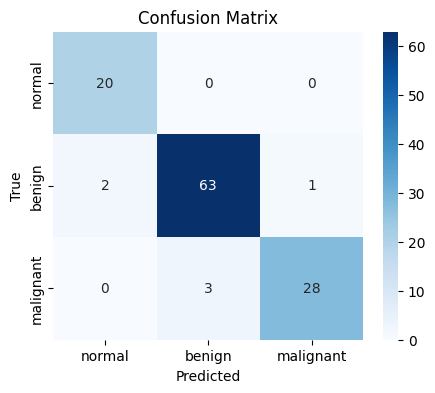

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(y_true, pred)
plt.figure(figsize=(5, 4))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=classes, yticklabels=classes)
plt.xlabel('Predicted')
plt.ylabel('True')
plt.title('Confusion Matrix')
plt.show()

## 8. ROC Curves

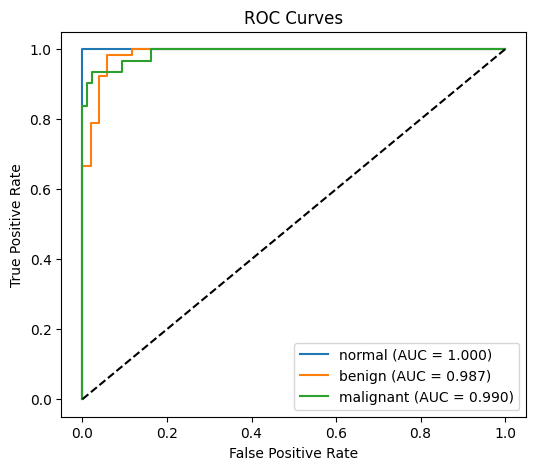

In [ ]:
from sklearn.metrics import roc_curve, auc

plt.figure(figsize=(6, 5))
for i, cls in enumerate(classes):
    fpr, tpr, _ = roc_curve(y_true == i, probs[:, i])
    plt.plot(fpr, tpr, label=f'{cls} (AUC = {auc(fpr, tpr):.3f})')
plt.plot([0, 1], [0, 1], 'k--')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curves')
plt.legend()
plt.show()

## 9. Training Loss

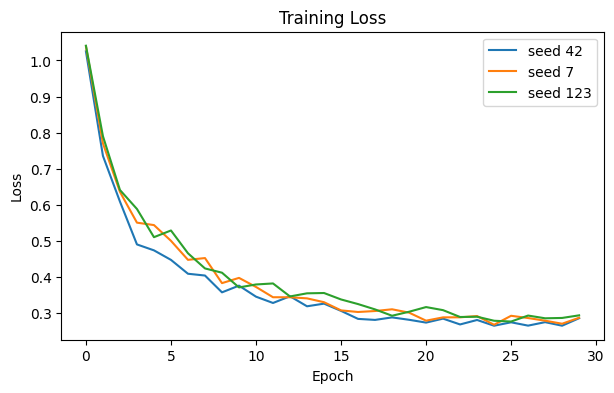

In [ ]:
plt.figure(figsize=(7, 4))
for seed, hist in zip([42, 7, 123], histories):
    plt.plot(hist, label=f'seed {seed}')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.title('Training Loss')
plt.legend()
plt.show()

## 10. Grad-CAM

Grad-CAM heatmaps of the ensemble. Red areas influenced the decision the most. The first row is one correctly classified image of each class, the second row is misclassified images.

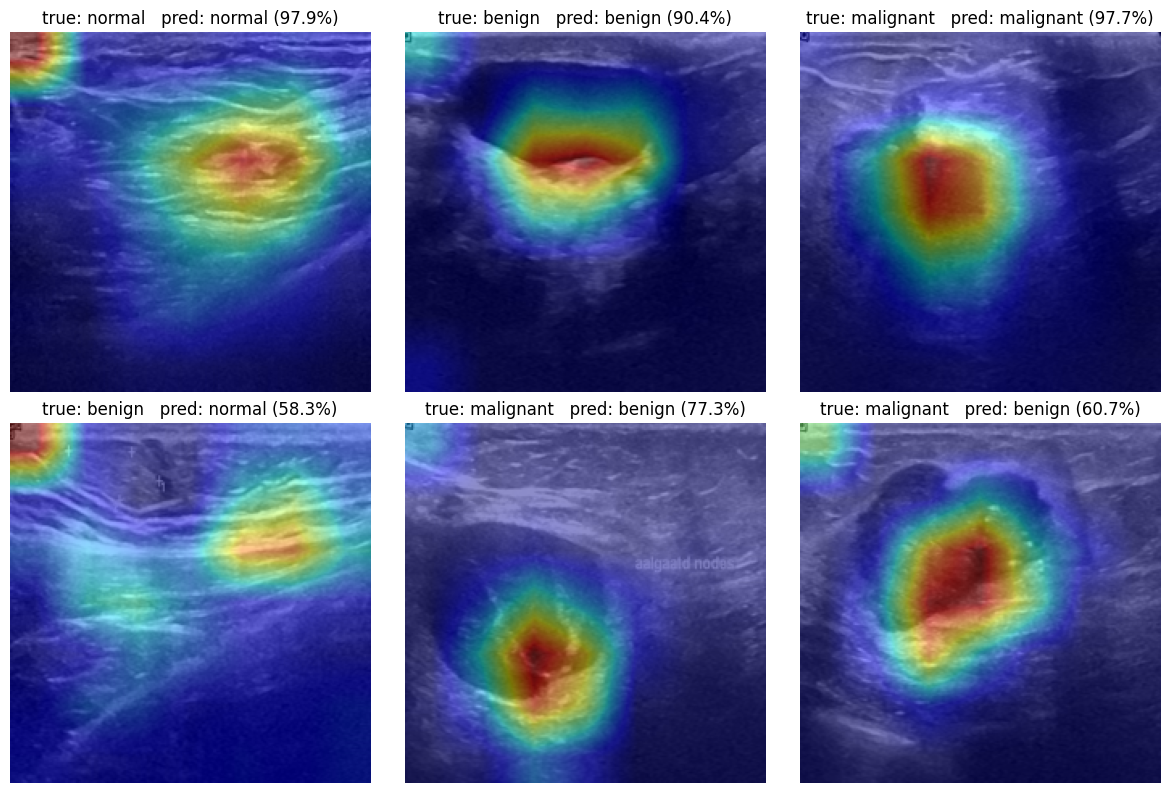

In [ ]:
def gradcam(model, img, cls):
    acts, grads = {}, {}
    layer = model.features[-1]
    h1 = layer.register_forward_hook(lambda m, i, o: acts.update(a=o))
    h2 = layer.register_full_backward_hook(lambda m, gi, go: grads.update(g=go[0]))
    x = test_tf(img).unsqueeze(0).to(device)
    model.zero_grad()
    out = model(x)
    out[0, cls].backward()
    w = grads['g'].mean(dim=(2, 3), keepdim=True)
    cam = torch.relu((w * acts['a']).sum(1))[0]
    cam = (cam - cam.min()) / (cam.max() - cam.min() + 1e-8)
    h1.remove(); h2.remove()
    cam = np.array(Image.fromarray((cam.detach().cpu().numpy() * 255).astype(np.uint8)).resize((224, 224), Image.BILINEAR)) / 255
    return cam

pick = [next(i for i in range(len(test_items)) if y_true[i] == c and pred[i] == c) for c in range(3)] + wrong[:3]
fig, axes = plt.subplots(2, 3, figsize=(12, 8))
for ax, i in zip(axes.flat, pick):
    img = Image.open(test_items[i][0]).convert('RGB')
    cam = np.mean([gradcam(m, img, int(pred[i])) for m in trained], axis=0)
    ax.imshow(img.resize((224, 224)))
    ax.imshow(cam, cmap='jet', alpha=0.45)
    ax.set_title(f"true: {classes[y_true[i]]}   pred: {classes[pred[i]]} ({probs[i].max() * 100:.1f}%)")
    ax.axis('off')
plt.tight_layout()
plt.show()

## 11. Misclassified Images

All the test images the ensemble classified wrongly.

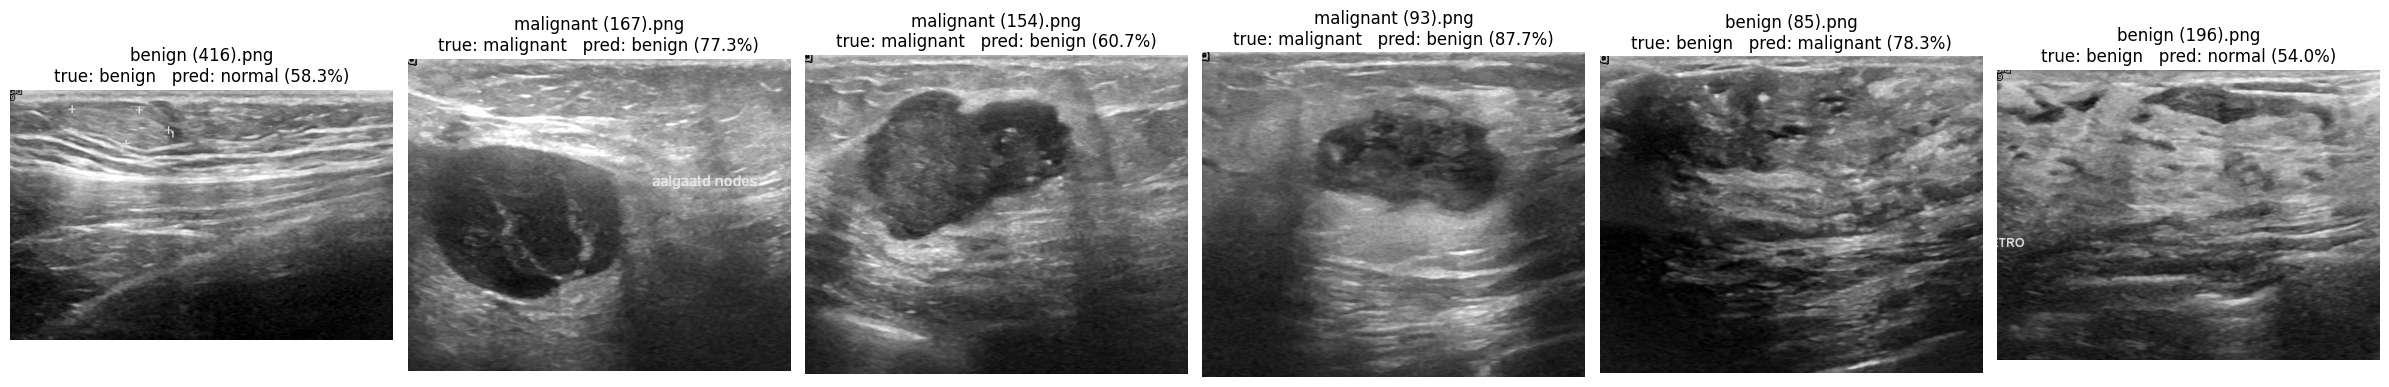

total errors: 6


In [ ]:
fig, axes = plt.subplots(1, len(wrong), figsize=(4 * len(wrong), 4))
if len(wrong) == 1:
    axes = [axes]
for ax, i in zip(axes, wrong):
    ax.imshow(Image.open(test_items[i][0]).convert('RGB'))
    ax.set_title(f"{test_items[i][0].name}\ntrue: {classes[y_true[i]]}   pred: {classes[pred[i]]} ({probs[i].max() * 100:.1f}%)")
    ax.axis('off')
plt.tight_layout()
plt.show()
print('total errors:', len(wrong))